In [25]:
"""
============================================
; Title: Classifying High Energy Use Buildings
; Author: Kat Chu
; Date: 27 September 2026
; Description: This notebook uses the ASHRAE Great Energy Predictor III dataset to
;              calculate how much electricity each building uses for its size, labels
;              buildings as high use or normal use, and trains logistic regression and
;              random forest models to predict which buildings are high use based on
;              building type, age, size, and weather.
;===========================================
"""

'\n============================================\n; Title: DSC680 Project 1 - Classifying High Energy Use Buildings\n; Author: Kat Chu\n; Date: 27 September 2026\n; Description: This notebook uses the ASHRAE Great Energy Predictor III dataset to\n;              calculate how much electricity each building uses for its size, labels\n;              buildings as high use or normal use, and trains logistic regression and\n;              random forest models to predict which buildings are high use based on\n;              building type, age, size, and weather.\n;===========================================\n'

### Introduction
Building owners and facility managers usually only find out that a building is wasting energy when
they get a high utility bill. For this project I want to find out if I can predict which buildings use
more electricity than they should **for their size**, using basic information about the building and
its weather.

Bigger buildings obviously use more energy in total, so instead of total energy I use
**energy use per square foot** (kWh per square foot per year). Buildings in the top half are labeled
**high use** and the bottom half **normal use**.

**Research questions**
1. Can I predict whether a building is a high energy user for its size using building type, age, size,
   and weather?
2. Which model works better for this problem, logistic regression or random forest?
3. Which building features matter most for whether a building is high use?

**How to run:** run this notebook on Kaggle with the ASHRAE Great Energy Predictor III competition data
attached. It finds the data on its own and takes about 5 minutes. The last cell prints a summary of all
the results.

In [26]:
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc

#colors I use for all the figures
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8984'

In [27]:
#Finding the competition data folder on Kaggle
found = glob.glob('/kaggle/input/**/building_metadata.csv', recursive=True)
if os.environ.get('ASHRAE_DATA'):
    DATA_DIR = os.environ['ASHRAE_DATA']
elif found:
    DATA_DIR = os.path.dirname(found[0])
else:
    DATA_DIR = '.'
print('Data folder:', DATA_DIR)

Data folder: /kaggle/input/competitions/ashrae-energy-prediction


In [28]:
#Loading the three files
#train.csv has about 20 million rows so I set the data types to save memory
meters = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'),
                     dtype={'building_id': 'int16', 'meter': 'int8', 'meter_reading': 'float32'})
meters['timestamp'] = pd.to_datetime(meters['timestamp'])
buildings = pd.read_csv(os.path.join(DATA_DIR, 'building_metadata.csv'))
weather = pd.read_csv(os.path.join(DATA_DIR, 'weather_train.csv'))

print('train.csv:', meters.shape)
print('building_metadata.csv:', buildings.shape)
print('weather_train.csv:', weather.shape)
buildings.head()

train.csv: (20216100, 4)
building_metadata.csv: (1449, 6)
weather_train.csv: (139773, 9)


,site_id,building_id,primary_use,square_feet,year_built,floor_count
0,0,0,Education,7432,2008.0,NaN
1,0,1,Education,2720,2004.0,NaN
2,0,2,Education,5376,1991.0,NaN
3,0,3,Education,23685,2002.0,NaN
4,0,4,Education,116607,1975.0,NaN


### Data Dictionary (key fields)

| Field | Description |
|---|---|
| building_id | Unique ID for each building |
| site_id | Which site (campus) the building is on, used to join the weather |
| meter_reading | Energy used in one hour (kWh for electricity) |
| primary_use | Main use of the building (Education, Office, Lodging, etc.) |
| square_feet | Floor area of the building |
| year_built | Year the building was built (missing for about half) |
| floor_count | Number of floors (mostly missing) |
| air_temperature | Outdoor temperature in °C |
| **kwh_per_sqft** | Created: electricity used per square foot per year |
| **high_use** | Created: 1 if kwh_per_sqft is above the median, 0 if not (the target) |

---
# Data Preparation
---

In [29]:
#Keeping a count of rows and buildings after each step for the paper
cleaning_log = []
def log_step(step, df):
    cleaning_log.append({'step': step, 'rows': len(df), 'buildings': df['building_id'].nunique()})
    print(f'{step}: {len(df):,} rows, {df["building_id"].nunique():,} buildings')

log_step('Raw train.csv (all meter types)', meters)

#Step 1: keeping only electricity (meter 0), since every building has an electricity meter
elec = meters[meters['meter'] == 0].drop(columns='meter').copy()
del meters
log_step('Electricity only', elec)

#Step 2: site 0 electricity was recorded in kBTU instead of kWh, so I convert it (1 kBTU = 0.2931 kWh)
elec = elec.merge(buildings[['building_id', 'site_id']], on='building_id', how='left')
elec.loc[elec['site_id'] == 0, 'meter_reading'] *= 0.2931

#Step 3: checking for duplicate readings
print('Duplicate rows:', elec.duplicated(subset=['building_id', 'timestamp']).sum())
elec = elec.drop_duplicates(subset=['building_id', 'timestamp'])

Raw train.csv (all meter types): 20,216,100 rows, 1,449 buildings
Electricity only: 12,060,910 rows, 1,413 buildings
Duplicate rows: 0


In [30]:
#Step 4: removing long stretches of zeros
#A building can't really use zero electricity for 2 days straight, so this means the meter was off or broken
elec = elec.sort_values(['building_id', 'timestamp']).reset_index(drop=True)
is_zero = elec['meter_reading'] == 0
#giving each stretch of zeros / non-zeros its own number so I can count how long it lasts
run_id = ((is_zero != is_zero.shift()) | (elec['building_id'] != elec['building_id'].shift())).cumsum()
run_length = is_zero.groupby(run_id).transform('size')
remove = is_zero & (run_length >= 48)
print(f'Zero readings removed: {remove.sum():,} ({remove.mean()*100:.1f}%)')
elec = elec[~remove]
log_step('After removing 48+ hour zero stretches', elec)

#Step 5: removing single hours that are more than 10x the building's normal (median) reading
median_reading = elec.groupby('building_id')['meter_reading'].transform('median')
spike = (median_reading > 0) & (elec['meter_reading'] > 10 * median_reading)
print(f'Spike readings removed: {spike.sum():,}')
elec = elec[~spike]
log_step('After removing spikes', elec)

Zero readings removed: 459,015 (3.8%)
After removing 48+ hour zero stretches: 11,601,895 rows, 1,413 buildings
Spike readings removed: 26,536
After removing spikes: 11,575,359 rows, 1,413 buildings


In [31]:
#Step 6: turning the hourly readings into one row per building
#I use the average hourly reading x 8,760 hours in a year, so buildings with a few missing hours
#are not unfairly counted as using less energy
per_building = elec.groupby('building_id')['meter_reading'].agg(avg_hourly_kwh='mean', hours='count').reset_index()
per_building['yearly_kwh'] = per_building['avg_hourly_kwh'] * 8760

#Only keeping buildings with at least half a year of good readings (4,380 hours)
per_building = per_building[per_building['hours'] >= 4380]
log_step('Buildings with at least half a year of readings', per_building)

#Step 7: adding the weather - the average temperature at each site for the year
site_temp = weather.groupby('site_id')['air_temperature'].mean().rename('avg_temp').reset_index()

#Step 8: joining everything into one table
df = per_building.merge(buildings, on='building_id', how='left').merge(site_temp, on='site_id', how='left')

#Step 9: energy use per square foot, and the high use label
df['kwh_per_sqft'] = df['yearly_kwh'] / df['square_feet']
#dropping buildings that used no electricity at all
df = df[df['kwh_per_sqft'] > 0]
median_use = df['kwh_per_sqft'].median()
df['high_use'] = (df['kwh_per_sqft'] > median_use).astype(int)
log_step('Final building table', df)

print(f'\nMedian energy use: {median_use:.1f} kWh per square foot per year')
print(df['high_use'].value_counts())
df[['building_id', 'primary_use', 'square_feet', 'year_built', 'avg_temp', 'kwh_per_sqft', 'high_use']].head()

Buildings with at least half a year of readings: 1,391 rows, 1,391 buildings
Final building table: 1,391 rows, 1,391 buildings

Median energy use: 11.5 kWh per square foot per year
high_use
0    696
1    695
Name: count, dtype: int64


,building_id,primary_use,square_feet,year_built,avg_temp,kwh_per_sqft,high_use
0,0,Education,7432,2008.0,22.836021,81.668049,1
1,1,Education,2720,2004.0,22.836021,80.545094,1
2,2,Education,5376,1991.0,22.836021,11.215509,0
3,3,Education,23685,2002.0,22.836021,41.482560,1
4,4,Education,116607,1975.0,22.836021,33.265168,1


In [32]:
#Checking for missing values in the features I plan to use
print(df[['primary_use', 'square_feet', 'year_built', 'floor_count', 'avg_temp']].isnull().sum())

primary_use       0
square_feet       0
year_built      740
floor_count    1051
avg_temp          0
dtype: int64


### Exploring the data

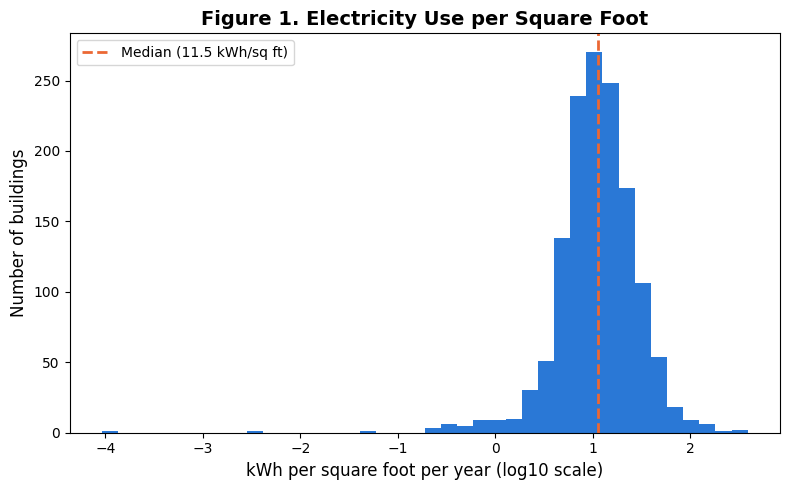

In [33]:
#Figure 1: distribution of energy use per square foot
plt.figure(figsize=(8, 5))
plt.hist(np.log10(df['kwh_per_sqft']), bins=40, color=BLUE)
plt.axvline(np.log10(median_use), color=ORANGE, linestyle='--', linewidth=2, label=f'Median ({median_use:.1f} kWh/sq ft)')
plt.title('Figure 1. Electricity Use per Square Foot', fontsize=14, fontweight='bold')
plt.xlabel('kWh per square foot per year (log10 scale)', fontsize=12)
plt.ylabel('Number of buildings', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('fig1_kwh_per_sqft.png', dpi=200)
plt.show()

#Energy use per square foot is very spread out, so I show it on a log scale
#Buildings to the right of the orange line are labeled high use

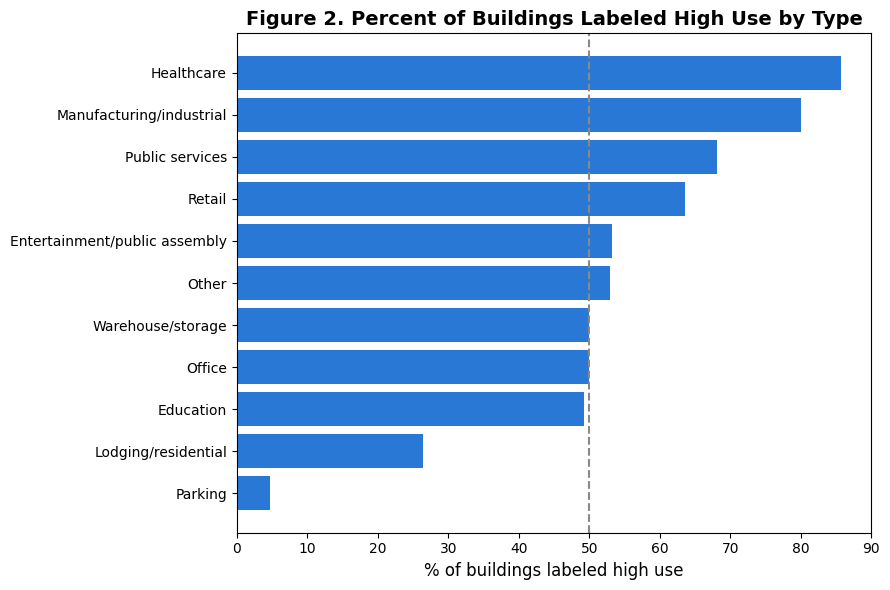

use_group
Parking                           4.8
Lodging/residential              26.4
Education                        49.2
Office                           50.0
Warehouse/storage                50.0
Other                            52.9
Entertainment/public assembly    53.2
Retail                           63.6
Public services                  68.2
Manufacturing/industrial         80.0
Healthcare                       85.7
Name: high_use, dtype: float64


In [34]:
#Figure 2: which building types are most often high use
#Building types with fewer than 10 buildings are grouped into Other
counts = df['primary_use'].value_counts()
df['use_group'] = df['primary_use'].where(df['primary_use'].map(counts) >= 10, 'Other')
pct_high = (df.groupby('use_group')['high_use'].mean() * 100).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(pct_high.index, pct_high.values, color=BLUE)
plt.axvline(50, color=GRAY, linestyle='--')
plt.title('Figure 2. Percent of Buildings Labeled High Use by Type', fontsize=14, fontweight='bold')
plt.xlabel('% of buildings labeled high use', fontsize=12)
plt.tight_layout()
plt.savefig('fig2_high_use_by_type.png', dpi=200)
plt.show()
print(pct_high.round(1))

### Preparing the features
- **primary_use** is turned into dummy (0/1) columns.
- **square_feet** is log transformed since a few buildings are huge.
- **year_built** and **floor_count** are missing for many buildings, so I fill the missing values with
  the median and add a 0/1 column that says the value was missing. That way I don't lose half the buildings.
- **avg_temp** is the average outdoor temperature at the building's site.

In [35]:
X = pd.DataFrame({
    'log_square_feet': np.log10(df['square_feet']),
    'year_built': df['year_built'].fillna(df['year_built'].median()),
    'year_built_missing': df['year_built'].isnull().astype(int),
    'floor_count': df['floor_count'].fillna(df['floor_count'].median()).fillna(0),
    'floor_count_missing': df['floor_count'].isnull().astype(int),
    'avg_temp': df['avg_temp'].fillna(df['avg_temp'].median()),
})
X = pd.concat([X, pd.get_dummies(df['use_group'], prefix='type').astype(int)], axis=1)
y = df['high_use']

#Splitting into 80% training and 20% testing, keeping the same high/normal balance in both
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Training set:', X_train.shape, ' Test set:', X_test.shape)
print('Features:', X.columns.tolist())

Training set: (1112, 17)  Test set: (279, 17)
Features: ['log_square_feet', 'year_built', 'year_built_missing', 'floor_count', 'floor_count_missing', 'avg_temp', 'type_Education', 'type_Entertainment/public assembly', 'type_Healthcare', 'type_Lodging/residential', 'type_Manufacturing/industrial', 'type_Office', 'type_Other', 'type_Parking', 'type_Public services', 'type_Retail', 'type_Warehouse/storage']


---
# Methods
---
This is a binary classification problem (high use vs. normal use), so I used two classification models:

- **Logistic regression** is simple and easy to explain. Each feature gets a coefficient that shows
  whether it makes a building more or less likely to be high use. I have used it in earlier projects and it worked well.
- **Random forest** builds many decision trees and combines them. It can pick up non-linear patterns
  (for example, a building type that is only high use in hot climates) and gives a feature importance score.

I also thought about the time series approach from my proposal (Prophet), but predicting every building's
daily use turned out to be much more complicated than needed to answer the main question of which buildings
use too much energy.

**Validation:** 80/20 train/test split, 5-fold cross-validation on the training set, and accuracy,
precision, recall, confusion matrix, and ROC/AUC on the test set. The classes are balanced (split at the
median), so accuracy is a fair measure here.

In [36]:
#Logistic regression (the features are scaled first so the coefficients can be compared)
log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
#Random forest
rf_model = RandomForestClassifier(n_estimators=300, random_state=42)

results = {}
for name, model in [('Logistic Regression', log_model), ('Random Forest', rf_model)]:
    #5-fold cross-validation on the training data
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    results[name] = {'cv_mean': cv_scores.mean(), 'cv_std': cv_scores.std(),
                     'test_accuracy': accuracy_score(y_test, y_pred), 'auc': auc(fpr, tpr),
                     'y_pred': y_pred, 'fpr': fpr, 'tpr': tpr,
                     'report': classification_report(y_test, y_pred, target_names=['Normal', 'High use'], output_dict=True)}
    print(f'{name}')
    print(f'  5-fold CV accuracy: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})')
    print(f'  Test accuracy: {results[name]["test_accuracy"]:.3f}   AUC: {results[name]["auc"]:.3f}')
    print(classification_report(y_test, y_pred, target_names=['Normal', 'High use']))

Logistic Regression
  5-fold CV accuracy: 0.621 (+/- 0.025)
  Test accuracy: 0.624   AUC: 0.663
              precision    recall  f1-score   support

      Normal       0.64      0.57      0.60       140
    High use       0.61      0.68      0.64       139

    accuracy                           0.62       279
   macro avg       0.63      0.62      0.62       279
weighted avg       0.63      0.62      0.62       279

Random Forest
  5-fold CV accuracy: 0.642 (+/- 0.041)
  Test accuracy: 0.631   AUC: 0.674
              precision    recall  f1-score   support

      Normal       0.64      0.60      0.62       140
    High use       0.62      0.66      0.64       139

    accuracy                           0.63       279
   macro avg       0.63      0.63      0.63       279
weighted avg       0.63      0.63      0.63       279



---
# Analysis
---

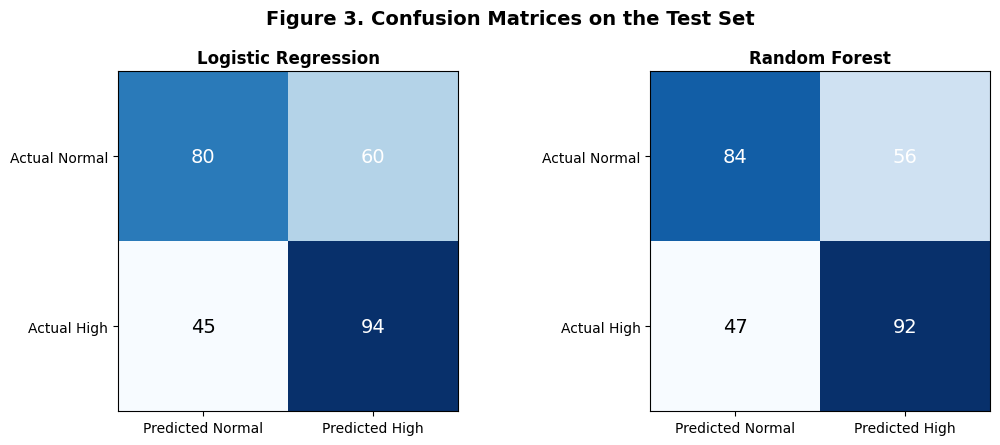

In [37]:
#Figure 3: confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, results):
    cm = confusion_matrix(y_test, results[name]['y_pred'])
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Predicted Normal', 'Predicted High'])
    ax.set_yticklabels(['Actual Normal', 'Actual High'])
    #writing the count in each box
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                    color='white' if cm[i, j] > cm.max() * 0.6 else 'black')
    ax.set_title(name, fontsize=12, fontweight='bold')
fig.suptitle('Figure 3. Confusion Matrices on the Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig3_confusion_matrices.png', dpi=200)
plt.show()

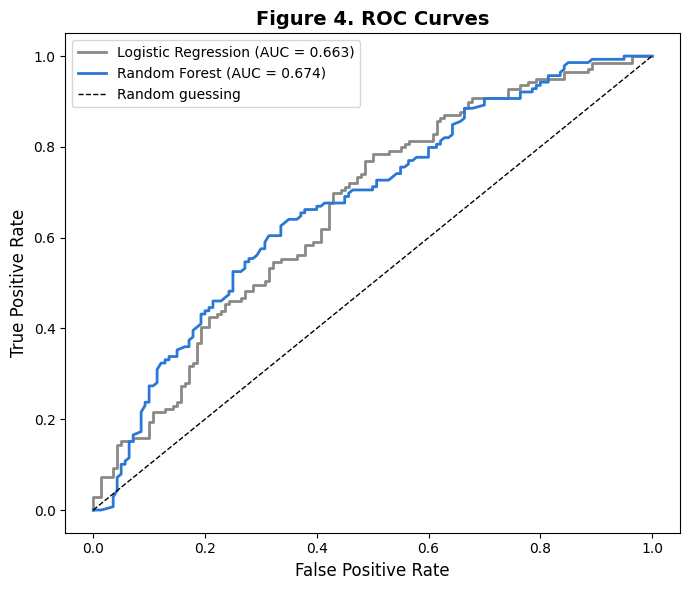

In [38]:
#Figure 4: ROC curves for both models
plt.figure(figsize=(7, 6))
for name, color in [('Logistic Regression', GRAY), ('Random Forest', BLUE)]:
    plt.plot(results[name]['fpr'], results[name]['tpr'], color=color, linewidth=2,
             label=f'{name} (AUC = {results[name]["auc"]:.3f})')
plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1, label='Random guessing')
plt.title('Figure 4. ROC Curves', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('fig4_roc_curves.png', dpi=200)
plt.show()

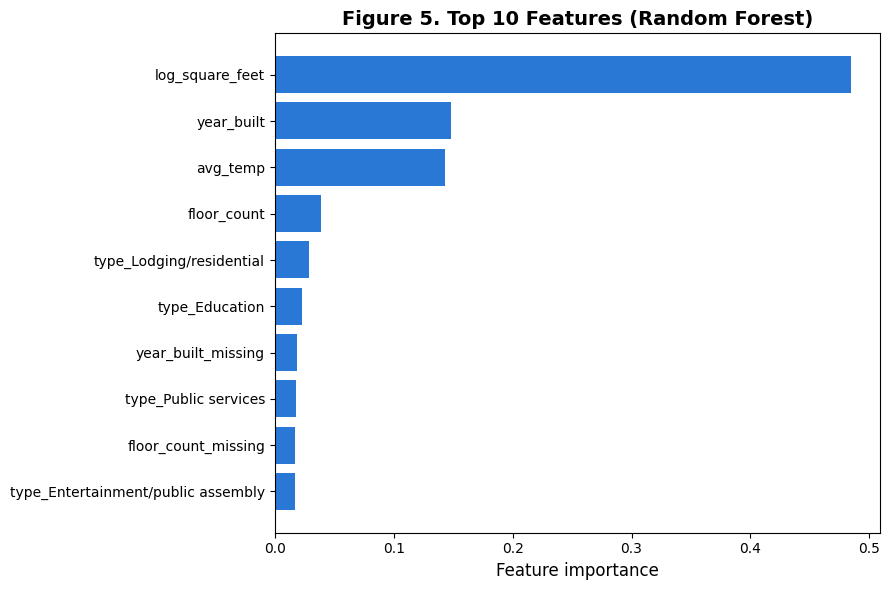

Logistic regression coefficients:
type_Lodging/residential             -0.375
type_Parking                         -0.337
log_square_feet                      -0.242
type_Office                          -0.057
type_Warehouse/storage               -0.032
type_Retail                           0.013
type_Entertainment/public assembly    0.016
type_Education                        0.049
avg_temp                              0.073
type_Other                            0.076
year_built_missing                    0.086
type_Manufacturing/industrial         0.197
type_Healthcare                       0.265
type_Public services                  0.271
floor_count_missing                   0.286
floor_count                           0.313
year_built                            0.330
dtype: float64


In [39]:
#Figure 5: which features matter most (random forest feature importance)
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
top = importance.tail(10)

plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color=BLUE)
plt.title('Figure 5. Top 10 Features (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Feature importance', fontsize=12)
plt.tight_layout()
plt.savefig('fig5_feature_importance.png', dpi=200)
plt.show()

#Logistic regression coefficients: positive = more likely high use, negative = less likely
coefs = pd.Series(log_model.named_steps['logisticregression'].coef_[0], index=X.columns).sort_values()
print('Logistic regression coefficients:')
print(coefs.round(3))

---
# Results Summary
---
The next cell prints all the numbers used in the white paper.

In [40]:
summary = {
    'cleaning_log': cleaning_log,
    'buildings': int(len(df)),
    'median_kwh_per_sqft': round(float(median_use), 2),
    'kwh_per_sqft_quartiles': df['kwh_per_sqft'].quantile([0.25, 0.5, 0.75]).round(2).tolist(),
    'pct_high_use_by_type': pct_high.round(1).to_dict(),
    'buildings_by_type': df['use_group'].value_counts().to_dict(),
    'train_size': int(len(X_train)), 'test_size': int(len(X_test)),
    'models': {name: {'cv_mean': round(r['cv_mean'], 3), 'cv_std': round(r['cv_std'], 3),
                      'test_accuracy': round(r['test_accuracy'], 3), 'auc': round(r['auc'], 3),
                      'precision_high': round(r['report']['High use']['precision'], 3),
                      'recall_high': round(r['report']['High use']['recall'], 3),
                      'precision_normal': round(r['report']['Normal']['precision'], 3),
                      'recall_normal': round(r['report']['Normal']['recall'], 3),
                      'confusion_matrix': confusion_matrix(y_test, r['y_pred']).tolist()}
               for name, r in results.items()},
    'rf_feature_importance': importance.sort_values(ascending=False).round(3).to_dict(),
    'logistic_coefficients': coefs.round(3).to_dict(),
    'year_built_missing_pct': round(float(df['year_built'].isnull().mean() * 100), 1),
}
print(json.dumps(summary, indent=1, default=str))

{
 "cleaning_log": [
  {
   "step": "Raw train.csv (all meter types)",
   "rows": 20216100,
   "buildings": 1449
  },
  {
   "step": "Electricity only",
   "rows": 12060910,
   "buildings": 1413
  },
  {
   "step": "After removing 48+ hour zero stretches",
   "rows": 11601895,
   "buildings": 1413
  },
  {
   "step": "After removing spikes",
   "rows": 11575359,
   "buildings": 1413
  },
  {
   "step": "Buildings with at least half a year of readings",
   "rows": 1391,
   "buildings": 1391
  },
  {
   "step": "Final building table",
   "rows": 1391,
   "buildings": 1391
  }
 ],
 "buildings": 1391,
 "median_kwh_per_sqft": 11.49,
 "kwh_per_sqft_quartiles": [
  6.83,
  11.49,
  19.15
 ],
 "pct_high_use_by_type": {
  "Parking": 4.8,
  "Lodging/residential": 26.4,
  "Education": 49.2,
  "Office": 50.0,
  "Warehouse/storage": 50.0,
  "Other": 52.9,
  "Entertainment/public assembly": 53.2,
  "Retail": 63.6,
  "Public services": 68.2,
  "Manufacturing/industrial": 80.0,
  "Healthcare": 85.7
 }